# Exploración de los datos de voz real

Fuente: **Open Speech Repository** (Telchemy), frases Harvard en inglés americano, 8 kHz.
Los archivos se descargan en `data/raw/` con `src/datos.py`.

In [1]:
import os, sys
sys.path.insert(0, os.path.join('..', 'src'))
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch
from datos import ARCHIVOS_OSR, cargar_voz
from signals import escenario, zumbido
fs = 8000
voces = {n: cargar_voz(n) for n in ARCHIVOS_OSR}

## 1. Características generales

In [2]:
for n, s in voces.items():
    rms = np.sqrt(np.mean(s**2))
    print(f'{n}: {len(s)/fs:5.1f} s | pico {np.max(np.abs(s)):.3f} | '
          f'RMS {rms:.4f} ({20*np.log10(rms):.1f} dBFS) | media {np.mean(s):+.5f}')

OSR_us_000_0010_8k.wav:  33.6 s | pico 0.328 | RMS 0.0433 (-27.3 dBFS) | media -0.00004
OSR_us_000_0030_8k.wav:  46.9 s | pico 0.542 | RMS 0.0404 (-27.9 dBFS) | media -0.00003


## 2. Forma de onda

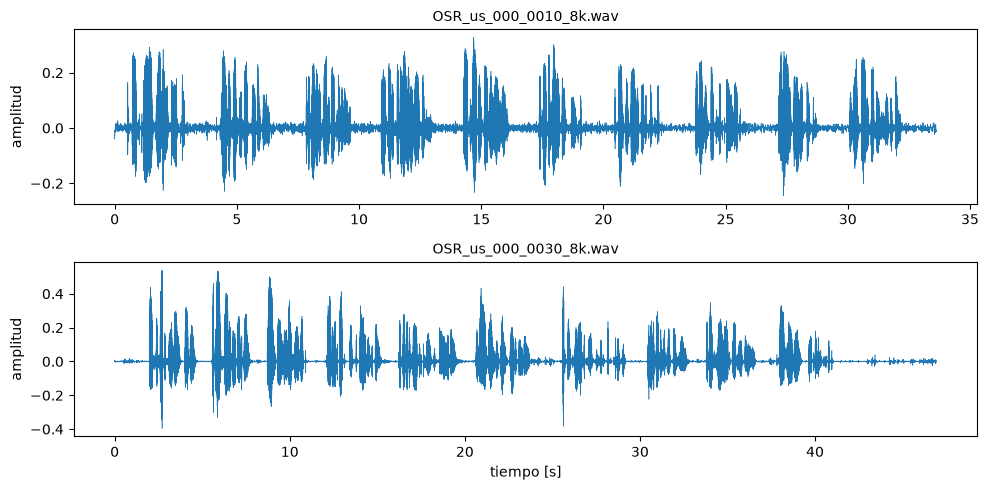

In [3]:
fig, ax = plt.subplots(len(voces), 1, figsize=(10, 5))
for a, (n, s) in zip(ax, voces.items()):
    a.plot(np.arange(len(s)) / fs, s, lw=0.4)
    a.set_title(n, fontsize=10); a.set_ylabel('amplitud')
ax[-1].set_xlabel('tiempo [s]')
plt.tight_layout()

## 3. Piso de ruido y silencios

Energía en tramas de 20 ms. El piso de ruido se estima con el percentil 5; una trama se considera silencio si está a menos de 6 dB del piso.

In [4]:
for n, s in voces.items():
    N = int(0.02 * fs)
    tramas = s[: len(s) // N * N].reshape(-1, N)
    e_db = 10 * np.log10(np.mean(tramas**2, axis=1) + 1e-12)
    piso = np.percentile(e_db, 5)
    silencio = np.mean(e_db < piso + 6)
    print(f'{n}: máximo {e_db.max():.1f} dB | piso {piso:.1f} dB | '
          f'rango dinámico {e_db.max()-piso:.1f} dB | silencio {100*silencio:.0f} %')

OSR_us_000_0010_8k.wav: máximo -15.9 dB | piso -48.2 dB | rango dinámico 32.3 dB | silencio 33 %
OSR_us_000_0030_8k.wav: máximo -13.2 dB | piso -61.3 dB | rango dinámico 48.1 dB | silencio 25 %


## 4. Espectro de la voz frente al zumbido

Si la voz tiene energía en las mismas frecuencias que el ruido, el filtro adaptativo recibe la voz como perturbación en esas bandas.

Energía de la voz entre 0 y 80 Hz: 2.4 %
Energía de la voz entre 80 y 260 Hz: 59.5 %
Energía de la voz entre 260 y 4000 Hz: 38.1 %


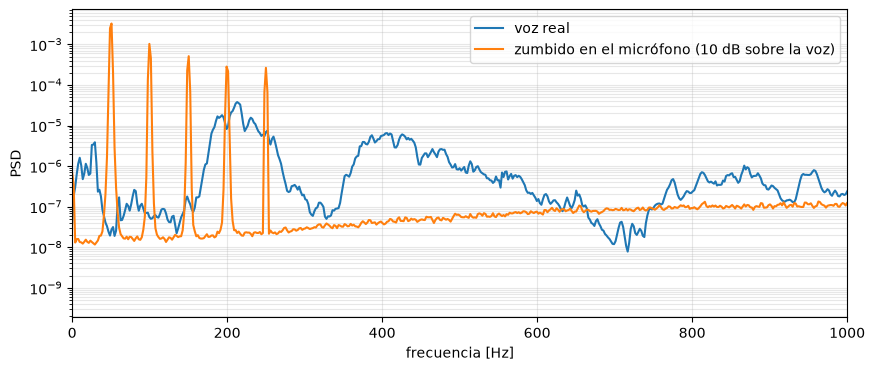

In [5]:
s = voces[ARCHIVOS_OSR[0]]
_, ruido = escenario(s, zumbido(len(s) / fs, fs))
f, p_voz = welch(s, fs, nperseg=4096)
_, p_zum = welch(ruido, fs, nperseg=4096)
fig, ax = plt.subplots(figsize=(10, 4))
ax.semilogy(f, p_voz, label='voz real')
ax.semilogy(f, p_zum, label='zumbido en el micrófono (10 dB sobre la voz)')
ax.set_xlim(0, 1000); ax.set_xlabel('frecuencia [Hz]'); ax.set_ylabel('PSD')
ax.legend(); ax.grid(alpha=0.3, which='both')
for a, b in [(0, 80), (80, 260), (260, fs / 2 + 1)]:
    pct = 100 * p_voz[(f >= a) & (f < b)].sum() / p_voz.sum()
    print(f'Energía de la voz entre {a:.0f} y {min(b, fs/2):.0f} Hz: {pct:.1f} %')

## 5. Espectrograma

Text(0.5, 1.0, 'OSR_us_000_0010_8k.wav')

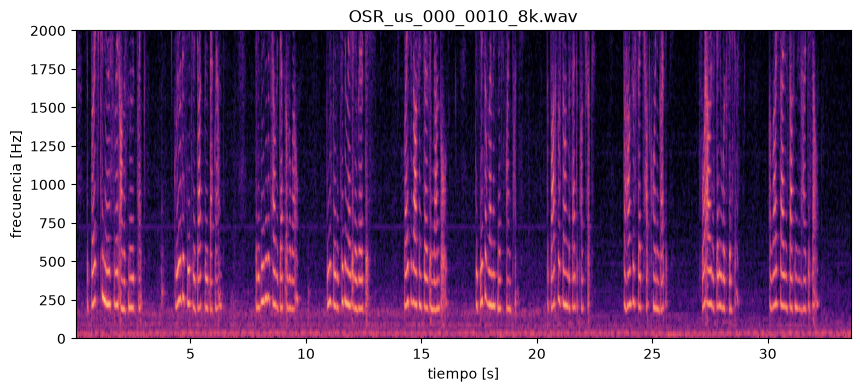

In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.specgram(s, NFFT=512, Fs=fs, noverlap=384, cmap='magma', vmin=-110, vmax=-20)
ax.set_ylim(0, 2000); ax.set_xlabel('tiempo [s]'); ax.set_ylabel('frecuencia [Hz]')
ax.set_title(ARCHIVOS_OSR[0])

## Observaciones

- Ambos archivos: 8 kHz, mono, nivel RMS ≈ −27 dBFS y sin componente continua.
- `OSR_us_000_0010` tiene un piso de ruido ~13 dB más alto que `OSR_us_000_0030` (rango dinámico 32 dB vs 48 dB): la "voz limpia" de referencia no es perfectamente limpia.
- Cerca del 60 % de la energía de la voz está entre 80 y 260 Hz (frecuencia fundamental), la misma banda de los armónicos del zumbido (100–250 Hz). Esto explica el desajuste de LMS/NLMS observado en `demo_hito2.py`: en esa banda la voz perturba la adaptación.
- Entre 25 % y 33 % de las tramas son silencio; en esos tramos el filtro adapta sin perturbación.